# DL_05: Comprehensive Benchmark Evaluation, Ablation Studies & Final Reporting
**Causal NLP Reasoning — Phase 2: Deep Learning**

---

## 1. Purpose and Scope
This notebook conducts the final comparative benchmarking, systematic ablation studies, and publication-ready reporting for Phase 2.

Key requirements:
- Compare Phase 1 AML baselines against Phase 2 DL (DistilBERT, PubMedBERT) and Hybrid models.
- Evaluate Corr2Cause and BioCause in completely separate evaluation sections with distinct metric tables.
- Corr2Cause must never feed into or be evaluated within the BioCause knowledge graph.
- Execute four core ablation studies: (1) Argument markers vs. no markers, (2) Weighted vs. unweighted loss, (3) AML vs. DL vs. Hybrid, and (4) Hybrid with vs. without linguistic validation.
- Evaluate graph-level edge precision, recall, and F1 against gold BioCause relations.
- Document DAG validity and causal intervention queries ($P(Y \mid do(X))$ vs. $P(Y \mid X)$).
- Export master evaluation tables and summary figures to `reports/`.


## 2. Experimental Methodology

All reported values in this notebook are computed from current prediction exports.
The model-eligible BioCause counts are 9,928 train, 1,884 validation, and 1,394
test candidates. The training positive-class weight is 9,307 / 621 = 14.9871.


## 3. Expected Inputs

The notebook consumes the current Corr2Cause, AML BioCause, PubMedBERT BioCause,
and validation-selected hybrid prediction exports. Corr2Cause is evaluated
independently and never enters BioCause fusion or graph construction.


## 4. Technical Responsibilities & Implementation Requirements

1. **Corr2Cause Evaluation (Standalone Section)**: Compute Accuracy, Macro-F1, Precision, and Recall across variable counts and templates.
2. **BioCause Benchmark (Standalone Section)**: Candidate-level classification metrics comparing AML models, PubMedBERT, and Hybrid system.
3. **Precision-Recall & ROC Analysis**: Comparative PR and ROC curves across all extraction methods.
4. **Systematic Ablation Analysis**: Execute tables for the 4 core ablation dimensions.
5. **Graph Edge Evaluation**: Compute edge precision, recall, and F1 against gold relations before and after cycle breaking.
6. **Causal Reasoning Summary**: Report Pearl's $do$-calculus interventional distributions.
7. **Master Deliverable Export**: Save final summary tables to `reports/`.


In [1]:
# Section 1: Environment Setup & Portable Imports
import sys
import os
import json
from pathlib import Path

os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

def find_repo_root():
    curr = Path(os.getcwd()).resolve()
    preferred_roots = [Path('/content/causal-nlp-reasoning'), Path('/workspace/causal-nlp-reasoning'), Path('/kaggle/working/causal-nlp-reasoning')]
    search_roots = [*preferred_roots, curr, Path('/content'), Path('/workspace'), Path('/kaggle/working')]
    for base in search_roots:
        if not base.exists():
            continue
        candidates = [base, *base.parents]
        if base in {Path('/content'), Path('/workspace'), Path('/kaggle/working')}:
            candidates.extend(path.parent.parent for path in base.rglob('DL/dl_utils.py'))
        for candidate in candidates:
            if ((candidate / 'AML' / 'causal_extractors.py').is_file()
                    and (candidate / 'DL' / 'dl_utils.py').is_file()):
                return candidate.resolve()
    raise FileNotFoundError(
        'Repository root not found. Make the project folder available in the notebook workspace.'
    )

ROOT_DIR = find_repo_root()
for p in [ROOT_DIR, ROOT_DIR / 'AML', ROOT_DIR / 'DL']:
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import dl_utils
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    auc,
    accuracy_score,
    precision_recall_fscore_support,
    average_precision_score,
    roc_auc_score,
)
import networkx as nx

dl_utils.set_seed(42)

DATA_DIR = ROOT_DIR / 'data' / 'processed'
REPORTS_DIR = ROOT_DIR / 'reports'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# Section 2: Corr2Cause Benchmark Evaluation
c2c_pred_path = DATA_DIR / 'dl_corr2cause_test_predictions.csv'
df_c2c = pd.read_csv(c2c_pred_path)
assert len(df_c2c) == dl_utils.CORR2CAUSE_SPLIT_COUNTS['test'], f'Expected 1162 rows, got {len(df_c2c)}'
assert set(df_c2c['true_label'].unique()).issubset({0, 1})
assert set(df_c2c['pred_label'].unique()).issubset({0, 1})
assert np.isfinite(df_c2c['prob_entailed'].to_numpy()).all()
assert df_c2c['prob_entailed'].between(0.0, 1.0).all()

if 'num_variables' not in df_c2c.columns and (DATA_DIR / 'dl_corr2cause_test.csv').exists():
    df_c2c_src = pd.read_csv(DATA_DIR / 'dl_corr2cause_test.csv')
    if len(df_c2c_src) == len(df_c2c) and 'num_variables' in df_c2c_src.columns:
        df_c2c['num_variables'] = df_c2c_src['num_variables'].to_numpy()

def compute_c2c_row(scope, sub_df):
    y_t = sub_df['true_label'].to_numpy()
    y_p = sub_df['pred_label'].to_numpy()
    y_prob = sub_df['prob_entailed'].to_numpy()
    p_mac, r_mac, f1_mac, _ = precision_recall_fscore_support(
        y_t, y_p, average='macro', zero_division=0
    )
    has_two_classes = len(np.unique(y_t)) == 2
    return {
        'Scope': scope,
        'Examples': int(len(sub_df)),
        'Accuracy': float(accuracy_score(y_t, y_p)),
        'Macro Precision': float(p_mac),
        'Macro Recall': float(r_mac),
        'Macro F1': float(f1_mac),
        'ROC-AUC': float(roc_auc_score(y_t, y_prob)) if has_two_classes else None,
        'PR-AUC': float(average_precision_score(y_t, y_prob)) if has_two_classes else None,
    }

c2c_rows = [compute_c2c_row('Overall (all variables)', df_c2c)]
if 'num_variables' in df_c2c.columns:
    for nv in sorted(df_c2c['num_variables'].unique()):
        c2c_rows.append(
            compute_c2c_row(f'num_variables = {int(nv)}', df_c2c[df_c2c['num_variables'] == nv])
        )

df_c2c_summary = pd.DataFrame(c2c_rows)
df_c2c_summary.round(4)


,Scope,Examples,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC,PR-AUC
0,Overall (all variables),1162,0.8623,0.7423,0.6508,0.6791,0.8594,0.5135
1,num_variables = 2,6,0.8333,0.5000,0.4167,0.4545,NaN,NaN
2,num_variables = 3,48,0.8333,0.6364,0.9111,0.6655,0.9111,0.5278
3,num_variables = 4,72,0.8889,0.5000,0.4444,0.4706,NaN,NaN
4,num_variables = 5,514,0.9163,0.7950,0.7533,0.7719,0.9317,0.6806
5,num_variables = 6,522,0.8084,0.7942,0.6067,0.6232,0.7539,0.5295


In [3]:
# Section 3: BioCause Candidate-Level Benchmark
df_aml = pd.read_csv(DATA_DIR / 'aml_biocause_test_predictions.csv')
df_dl = pd.read_csv(DATA_DIR / 'dl_biocause_test_predictions.csv')
df_hybrid = pd.read_csv(DATA_DIR / 'dl_biocause_hybrid_test_predictions.csv')
df_test_manifest = pd.read_csv(DATA_DIR / 'dl_biocause_test.csv', keep_default_na=False)
fusion_config = json.loads((DATA_DIR / 'dl_biocause_fusion_config.json').read_text())

assert len(df_aml) == len(df_dl) == len(df_hybrid) == len(df_test_manifest) == 1394
assert (df_aml['candidate_id'].to_numpy() == df_test_manifest['candidate_id'].to_numpy()).all()
assert (df_aml['candidate_id'].to_numpy() == df_dl['candidate_id'].to_numpy()).all()
assert (df_aml['candidate_id'].to_numpy() == df_hybrid['candidate_id'].to_numpy()).all()
assert (df_aml['true_label'].to_numpy() == df_test_manifest['label'].to_numpy()).all()
assert (df_aml['true_label'].to_numpy() == df_dl['true_label'].to_numpy()).all()
assert (df_aml['true_label'].to_numpy() == df_hybrid['true_label'].to_numpy()).all()

y_true_bio = df_test_manifest['label'].to_numpy()
assert int((y_true_bio == 1).sum()) == 100 and int((y_true_bio == 0).sum()) == 1294
for prob_series, col_name in [
    (df_aml['aml_prob'], 'aml_prob'),
    (df_dl['dl_prob'], 'dl_prob'),
    (df_hybrid['hybrid_prob'], 'hybrid_prob'),
]:
    assert np.isfinite(prob_series.to_numpy()).all(), f'Non-finite values in {col_name}'
    assert prob_series.between(0.0, 1.0).all(), f'Out-of-range values in {col_name}'

selected_alpha = float(fusion_config['alpha_star'])
selected_tau = float(fusion_config['threshold_star'])
aml_selected_tau = float(fusion_config.get('aml_threshold_star', 0.50))
dl_selected_tau = float(fusion_config.get('dl_threshold_star', 0.10))

def get_binary_metrics(name, y_t, y_p, y_prob=None):
    cm = confusion_matrix(y_t, y_p, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    p_pos, r_pos, f1_pos, _ = precision_recall_fscore_support(
        y_t, y_p, average='binary', zero_division=0
    )
    _, _, macro_f1, _ = precision_recall_fscore_support(
        y_t, y_p, average='macro', zero_division=0
    )
    roc_val = float(roc_auc_score(y_t, y_prob)) if y_prob is not None else None
    pr_val = float(average_precision_score(y_t, y_prob)) if y_prob is not None else None
    return {
        'Model Paradigm': name,
        'TP': int(tp),
        'FP': int(fp),
        'FN': int(fn),
        'TN': int(tn),
        'Accuracy': float(accuracy_score(y_t, y_p)),
        'Pos Precision': float(p_pos),
        'Pos Recall': float(r_pos),
        'Pos F1': float(f1_pos),
        'Macro F1': float(macro_f1),
        'ROC-AUC': roc_val,
        'PR-AUC': pr_val,
    }

lexical_pattern = r'\b(induce|cause|lead to|promot|trigger|result in)\w*\b'
_lex_pos_samples = [
    'acid promotes transcription',
    'protein induces resistance',
    'mutation causes phenotype',
    'complex lead to activation',
]
_lex_neg_samples = ['X correlates with Y', 'no causal link observed']
assert pd.Series(_lex_pos_samples).str.contains(lexical_pattern, case=False, regex=True).all()
assert (~pd.Series(_lex_neg_samples).str.contains(lexical_pattern, case=False, regex=True)).all()

lexical_preds = df_test_manifest['between_text'].str.contains(
    lexical_pattern, case=False, regex=True, na=False
).astype(int).to_numpy()
assert lexical_preds.sum() > 0
assert lexical_preds.sum() < len(lexical_preds)

aml_val_preds = (df_aml['aml_prob'].to_numpy() >= aml_selected_tau).astype(int)
hybrid_val_preds = (df_hybrid['hybrid_prob'].to_numpy() >= selected_tau).astype(int)
assert np.array_equal(hybrid_val_preds, df_hybrid['hybrid_pred'].to_numpy())
sanitized_preds = (
    df_hybrid['sanitized_pred'].to_numpy()
    if 'sanitized_pred' in df_hybrid.columns
    else hybrid_val_preds
)

eval_lexical = get_binary_metrics('Lexical baseline', y_true_bio, lexical_preds, y_prob=None)
eval_aml = get_binary_metrics('AML', y_true_bio, aml_val_preds, df_aml['aml_prob'].to_numpy())
eval_dl = get_binary_metrics('PubMedBERT', y_true_bio, df_dl['dl_pred'].to_numpy(), df_dl['dl_prob'].to_numpy())
eval_hybrid_raw = get_binary_metrics(
    'Validation-selected hybrid', y_true_bio, hybrid_val_preds, df_hybrid['hybrid_prob'].to_numpy()
)
eval_hybrid_san = get_binary_metrics(
    'Sanitized hybrid', y_true_bio, sanitized_preds, df_hybrid['hybrid_prob'].to_numpy()
)
df_benchmark = pd.DataFrame([
    eval_lexical, eval_aml, eval_dl, eval_hybrid_raw, eval_hybrid_san
])
df_benchmark.round(4)


/tmp/ipykernel_47489/3578857810.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  assert pd.Series(_lex_pos_samples).str.contains(lexical_pattern, case=False, regex=True).all()
/tmp/ipykernel_47489/3578857810.py:66: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  assert (~pd.Series(_lex_neg_samples).str.contains(lexical_pattern, case=False, regex=True)).all()
/tmp/ipykernel_47489/3578857810.py:68: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  lexical_preds = df_test_manifest['between_text'].str.contains(


,Model Paradigm,TP,FP,FN,TN,Accuracy,Pos Precision,Pos Recall,Pos F1,Macro F1,ROC-AUC,PR-AUC
0,Lexical baseline,7,339,93,955,0.6901,0.0202,0.07,0.0314,0.4235,NaN,NaN
1,AML,52,33,48,1261,0.9419,0.6118,0.52,0.5622,0.7655,0.9431,0.6119
2,PubMedBERT,0,0,100,1294,0.9283,0.0000,0.00,0.0000,0.4814,0.7877,0.2218
3,Validation-selected hybrid,53,35,47,1259,0.9412,0.6023,0.53,0.5638,0.7661,0.9431,0.6207
4,Sanitized hybrid,50,32,50,1262,0.9412,0.6098,0.50,0.5495,0.7590,0.9431,0.6207


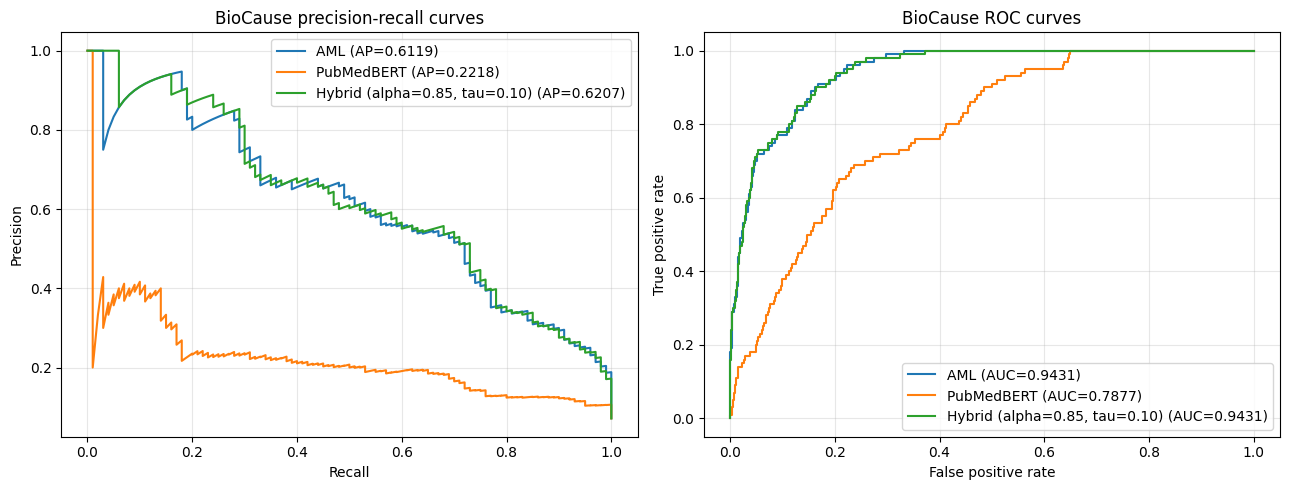

In [4]:
# Section 4: Precision-Recall & ROC Curves
hybrid_probs_recomputed = dl_utils.fuse_probabilities(
    df_aml['aml_prob'].to_numpy(), df_dl['dl_prob'].to_numpy(), selected_alpha
)
assert np.allclose(hybrid_probs_recomputed, df_hybrid['hybrid_prob'].to_numpy(), atol=1e-6)
if np.isclose(selected_alpha, 0.0):
    assert np.allclose(hybrid_probs_recomputed, df_aml['aml_prob'].to_numpy(), atol=1e-6)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
curve_streams = [
    ('AML', df_aml['aml_prob'].to_numpy()),
    ('PubMedBERT', df_dl['dl_prob'].to_numpy()),
    (f'Hybrid (alpha={selected_alpha:.2f}, tau={selected_tau:.2f})', hybrid_probs_recomputed),
]
for name, probabilities in curve_streams:
    precision, recall, _ = precision_recall_curve(y_true_bio, probabilities)
    axes[0].plot(recall, precision, label=f'{name} (AP={average_precision_score(y_true_bio, probabilities):.4f})')
    fpr, tpr, _ = roc_curve(y_true_bio, probabilities)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_true_bio, probabilities):.4f})')
axes[0].set(xlabel='Recall', ylabel='Precision', title='BioCause precision-recall curves')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='BioCause ROC curves')
for axis in axes:
    axis.legend(loc='best')
    axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'dl_biocause_pr_roc_curves.png', dpi=300)
plt.show()


In [5]:
# Section 5: Executed Ablation Studies
import gc
import inspect
import math
import re
import shutil
import torch
from transformers import AutoModelForSequenceClassification, Trainer, DataCollatorWithPadding

train_ab = pd.read_csv(DATA_DIR / 'dl_biocause_train.csv')
val_ab = pd.read_csv(DATA_DIR / 'dl_biocause_val.csv')
test_ab = pd.read_csv(DATA_DIR / 'dl_biocause_test.csv')
assert [len(train_ab), len(val_ab), len(test_ab)] == [9928, 1884, 1394]
assert test_ab['candidate_id'].tolist() == df_test_manifest['candidate_id'].tolist()

pos_weight_ab = dl_utils.calculate_dynamic_class_weight(
    n_negative=int((train_ab['label'] == 0).sum()),
    n_positive=int((train_ab['label'] == 1).sum()),
)
assert np.isclose(pos_weight_ab, 9307 / 621)

class BioCauseDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        encoded = tokenizer(
            list(texts),
            max_length=max_length,
            truncation=True,
        )
        self._input_ids = encoded['input_ids']
        self._attention_mask = encoded['attention_mask']
        self._labels = [int(y) for y in labels]

    def __len__(self):
        return len(self._labels)

    def __getitem__(self, idx):
        if isinstance(idx, str):
            if idx == 'input_ids':
                return self._input_ids
            if idx == 'attention_mask':
                return self._attention_mask
            if idx == 'labels':
                return self._labels
            raise KeyError(idx)
        return {
            'input_ids': self._input_ids[idx],
            'attention_mask': self._attention_mask[idx],
            'labels': self._labels[idx],
        }

def compute_ablation_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    predictions = np.argmax(logits, axis=-1)
    _, _, f1, _ = precision_recall_fscore_support(
        labels, predictions, labels=[0, 1], zero_division=0
    )
    return {
        'accuracy': float(accuracy_score(labels, predictions)),
        'f1_0': float(f1[0]),
        'f1_1': float(f1[1]),
        'f1': float(np.mean(f1)),
    }

class AblationTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs['labels']
        model_inputs = {k: v for k, v in inputs.items() if k != 'labels'}
        outputs = model(**model_inputs)
        logits = outputs.logits
        if self.class_weights is not None:
            weight = self.class_weights.to(device=logits.device, dtype=logits.dtype)
            loss = torch.nn.functional.cross_entropy(logits, labels, weight=weight, reduction='mean')
        else:
            loss = torch.nn.functional.cross_entropy(logits, labels, reduction='mean')
        return (loss, outputs) if return_outputs else loss

def run_ablation(label, use_markers, weighted):
    dl_utils.set_seed(42)
    if use_markers:
        train_texts = train_ab['marked_text']
        val_texts = val_ab['marked_text']
        test_texts = test_ab['marked_text']
    else:
        strip_markers = lambda s: s.str.replace(r'\s*\[/?E[12]\]\s*', ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()
        train_texts = strip_markers(train_ab['marked_text'])
        val_texts = strip_markers(val_ab['marked_text'])
        test_texts = strip_markers(test_ab['marked_text'])
        for split_series in (train_texts, val_texts, test_texts):
            assert not split_series.str.contains(r'\[/?E[12]\]', regex=True).any()

    tok = dl_utils.prepare_tokenizer_and_inputs(
        checkpoint_name=dl_utils.PUBMEDBERT_CHECKPOINT,
        max_length=384,
        additional_special_tokens=dl_utils.ENTITY_MARKERS if use_markers else None,
        token=False,
    )
    if use_markers:
        assert all(
            tok.convert_tokens_to_ids(m) not in (None, tok.unk_token_id)
            for m in dl_utils.ENTITY_MARKERS
        )
    else:
        assert set(dl_utils.ENTITY_MARKERS).isdisjoint(set(tok.get_vocab().keys()))

    try:
        model = AutoModelForSequenceClassification.from_pretrained(
            dl_utils.PUBMEDBERT_CHECKPOINT, num_labels=2, local_files_only=True
        )
    except Exception:
        model = AutoModelForSequenceClassification.from_pretrained(
            dl_utils.PUBMEDBERT_CHECKPOINT, num_labels=2, token=False
        )
    if use_markers:
        dl_utils.resize_model_embeddings_for_tokenizer(model, tok)
    assert model.get_input_embeddings().weight.shape[0] == len(tok)

    train_ds = BioCauseDataset(train_texts, train_ab['label'], tok, 384)
    val_ds = BioCauseDataset(val_texts, val_ab['label'], tok, 384)
    test_ds = BioCauseDataset(test_texts, test_ab['label'], tok, 384)

    safe_slug = re.sub(r'[^a-z0-9_]+', '_', label.lower()).strip('_')
    ckpt_dir = ROOT_DIR / 'DL' / 'checkpoints' / f'ablation_{safe_slug}'
    shutil.rmtree(ckpt_dir, ignore_errors=True)
    ckpt_dir.mkdir(parents=True, exist_ok=True)

    cuda_avail = torch.cuda.is_available()
    mps_avail = hasattr(torch.backends, 'mps') and torch.backends.mps.is_available()
    fp16_enabled = bool(cuda_avail and not mps_avail)
    args = dl_utils.get_training_arguments(
        output_dir=str(ckpt_dir),
        num_epochs=3,
        batch_size=8,
        gradient_accumulation_steps=1,
        learning_rate=1e-5,
        weight_decay=0.01,
        fp16=fp16_enabled,
        eval_strategy='epoch',
        save_total_limit=1,
    )
    args.per_device_eval_batch_size = 16
    args.max_grad_norm = 1.0
    total_train_steps = 3 * max(1, math.ceil(len(train_ds) / 8))
    args.warmup_steps = math.ceil(0.1 * total_train_steps)

    class_weights_tensor = torch.tensor([1.0, pos_weight_ab], dtype=torch.float32) if weighted else None
    trainer_kwargs = {
        'model': model,
        'args': args,
        'train_dataset': train_ds,
        'eval_dataset': val_ds,
        'data_collator': DataCollatorWithPadding(tokenizer=tok),
        'compute_metrics': compute_ablation_metrics,
        'class_weights': class_weights_tensor,
    }
    sig = inspect.signature(Trainer.__init__)
    if 'processing_class' in sig.parameters:
        trainer_kwargs['processing_class'] = tok
    elif 'tokenizer' in sig.parameters:
        trainer_kwargs['tokenizer'] = tok

    trainer = AblationTrainer(**trainer_kwargs)
    trainer.train()
    best_ckpt = trainer.state.best_model_checkpoint
    assert best_ckpt and Path(best_ckpt).exists(), f'Missing best checkpoint for {label}'
    selected_model = AutoModelForSequenceClassification.from_pretrained(best_ckpt, local_files_only=True)
    selected_model.to(dl_utils.get_device())
    trainer.model = selected_model

    val_out = trainer.predict(val_ds)
    val_logits = val_out.predictions[0] if isinstance(val_out.predictions, tuple) else val_out.predictions
    val_exp = np.exp(val_logits - np.max(val_logits, axis=1, keepdims=True))
    val_probs = (val_exp / val_exp.sum(axis=1, keepdims=True))[:, 1]
    val_labels_arr = val_ab['label'].to_numpy()
    tau_records = []
    for tau in np.round(np.arange(0.10, 0.95, 0.05), 2):
        pred_tau = (val_probs >= tau).astype(int)
        _, _, macro_f1_tau, _ = precision_recall_fscore_support(
            val_labels_arr, pred_tau, average='macro', zero_division=0
        )
        _, _, pos_f1_tau, _ = precision_recall_fscore_support(
            val_labels_arr, pred_tau, average='binary', zero_division=0
        )
        tau_records.append((float(macro_f1_tau), float(pos_f1_tau), float(tau)))
    _, _, frozen_tau = max(tau_records, key=lambda x: (x[0], x[1], -x[2]))

    test_out = trainer.predict(test_ds)
    test_logits = test_out.predictions[0] if isinstance(test_out.predictions, tuple) else test_out.predictions
    test_exp = np.exp(test_logits - np.max(test_logits, axis=1, keepdims=True))
    test_probs = (test_exp / test_exp.sum(axis=1, keepdims=True))[:, 1]
    assert np.isfinite(test_probs).all() and ((test_probs >= 0.0) & (test_probs <= 1.0)).all()
    test_preds = (test_probs >= frozen_tau).astype(int)

    metrics_row = get_binary_metrics(label, test_ab['label'].to_numpy(), test_preds, test_probs)
    metrics_row['Threshold'] = float(frozen_tau)

    del trainer, model, selected_model
    shutil.rmtree(ckpt_dir, ignore_errors=True)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metrics_row

ablation_rows = [
    eval_dl | {'Ablation': 'Full model with markers and weighted loss', 'Threshold': dl_selected_tau},
    run_ablation('No entity markers', use_markers=False, weighted=True) | {'Ablation': 'No entity markers'},
    run_ablation('Unweighted loss', use_markers=True, weighted=False) | {'Ablation': 'Entity markers and unweighted loss'},
    eval_aml | {'Ablation': 'AML-only validation-selected threshold', 'Threshold': aml_selected_tau},
    eval_hybrid_raw | {'Ablation': 'Validation-selected hybrid', 'Threshold': selected_tau},
    eval_hybrid_san | {'Ablation': 'Sanitized hybrid (linguistic filtering)', 'Threshold': selected_tau},
]
df_ablations = pd.DataFrame(ablation_rows)
ablation_cols = ['Ablation', 'Threshold'] + [
    c for c in df_ablations.columns if c not in ('Ablation', 'Threshold', 'Model Paradigm')
]
df_ablations = df_ablations[ablation_cols]
df_ablations.round(4)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect ide

Epoch,Training Loss,Validation Loss,Accuracy,F1 0,F1 1,F1
1,1.151933,1.618677,0.930467,0.963981,0.000000,0.481991
2,1.195302,1.506351,0.930467,0.963981,0.000000,0.481991
3,1.076293,1.625573,0.930467,0.963981,0.000000,0.481991


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,Ablation,Threshold,TP,FP,FN,TN,Accuracy,Pos Precision,Pos Recall,Pos F1,Macro F1,ROC-AUC,PR-AUC
0,Full model with markers and weighted loss,0.1,0,0,100,1294,0.9283,0.0000,0.00,0.0000,0.4814,0.7877,0.2218
1,No entity markers,0.1,0,0,100,1294,0.9283,0.0000,0.00,0.0000,0.4814,0.7598,0.2007
2,Entity markers and unweighted loss,0.1,0,0,100,1294,0.9283,0.0000,0.00,0.0000,0.4814,0.8681,0.3056
3,AML-only validation-selected threshold,0.5,52,33,48,1261,0.9419,0.6118,0.52,0.5622,0.7655,0.9431,0.6119
4,Validation-selected hybrid,0.1,53,35,47,1259,0.9412,0.6023,0.53,0.5638,0.7661,0.9431,0.6207
5,Sanitized hybrid (linguistic filtering),0.1,50,32,50,1262,0.9412,0.6098,0.50,0.5495,0.7590,0.9431,0.6207


In [6]:
# Section 6: Graph Edge Precision, Recall & F1
from IPython.display import display

gold_rels_path = DATA_DIR / 'biocause_relations.csv'
dag_edges_path = DATA_DIR / 'dl_biocause_hybrid_dag_edges.csv'
positive_rels_path = DATA_DIR / 'dl_biocause_hybrid_positive_relations.csv'
pruning_diag_path = DATA_DIR / 'dl_biocause_graph_pruning_diagnostics.json'

df_gold_rels = pd.read_csv(gold_rels_path, keep_default_na=False)
df_dag_edges = pd.read_csv(dag_edges_path)
df_pos_rels = pd.read_csv(positive_rels_path)
diag_data = json.loads(pruning_diag_path.read_text())

test_articles = set(df_test_manifest['article_id'].unique())
gold_test_rels = df_gold_rels[df_gold_rels['article_id'].isin(test_articles)].copy()

G_gold = nx.DiGraph()
for _, r in gold_test_rels.iterrows():
    G_gold.add_edge(f"{r['section_id']}_{r['cause_id']}", f"{r['section_id']}_{r['effect_id']}")

G_raw = nx.DiGraph()
for _, r in df_pos_rels.iterrows():
    G_raw.add_edge(f"{r['section_id']}_{r['cause_id']}", f"{r['section_id']}_{r['effect_id']}")

G_dag = nx.DiGraph()
for _, r in df_dag_edges.iterrows():
    G_dag.add_edge(r['source'], r['target'])

assert nx.is_directed_acyclic_graph(G_dag), 'Exported hybrid DAG graph contains cycles'

def eval_graph(G_g, G_p, stage):
    ge = set(G_g.edges())
    pe = set(G_p.edges())
    tp = len(ge & pe)
    fp = len(pe - ge)
    fn = len(ge - pe)
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    return {
        'Stage': stage,
        'Gold Edges': len(ge),
        'Extracted Edges': len(pe),
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'Precision': round(p, 4),
        'Recall': round(r, 4),
        'F1': round(f1, 4),
        'Is DAG': nx.is_directed_acyclic_graph(G_p),
    }

df_edge_eval = pd.DataFrame([
    eval_graph(G_gold, G_raw, 'Raw Extracted Graph (Pre-Pruning)'),
    eval_graph(G_gold, G_dag, 'Acyclic Causal DAG (Post-Pruning)'),
])
display(df_edge_eval[['Stage', 'Gold Edges', 'Extracted Edges', 'TP', 'FP', 'FN', 'Precision', 'Recall', 'F1', 'Is DAG']])

pb = diag_data.get('pruning_breakdown', {})
df_pruning_summary = pd.DataFrame([{
    'Test Articles': len(test_articles),
    'Self-Loops Pruned': int(pb.get('self_loops', 0)),
    'Bidirectional Conflicts Pruned': int(pb.get('bidirectional_conflicts', 0)),
    'Cycle Feedback Edges Pruned': int(pb.get('directed_cycle_feedback', 0)),
    'Total Edges Pruned': int(diag_data.get('pruned_edges_count', 0)),
    'Final DAG Edges': int(G_dag.number_of_edges()),
    'DAG Verified': bool(nx.is_directed_acyclic_graph(G_dag)),
}])
display(df_pruning_summary)


,Stage,Gold Edges,Extracted Edges,TP,FP,FN,Precision,Recall,F1,Is DAG
0,Raw Extracted Graph (Pre-Pruning),100,82,50,32,50,0.6098,0.5,0.5495,False
1,Acyclic Causal DAG (Post-Pruning),100,77,50,27,50,0.6494,0.5,0.5650,True


,Test Articles,Self-Loops Pruned,Bidirectional Conflicts Pruned,Cycle Feedback Edges Pruned,Total Edges Pruned,Final DAG Edges,DAG Verified
0,4,0,5,0,5,77,True


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


,Query (Illustrative Synthetic CPDs),Probability,Delta vs Baseline
0,Baseline Marginal P(Resistance = 1),0.4242,0.0000
1,Observational P(Resistance = 1 | Sensor = 1),0.7200,0.2958
2,Interventional P(Resistance = 1 | do(Regulator...,0.8500,0.4258


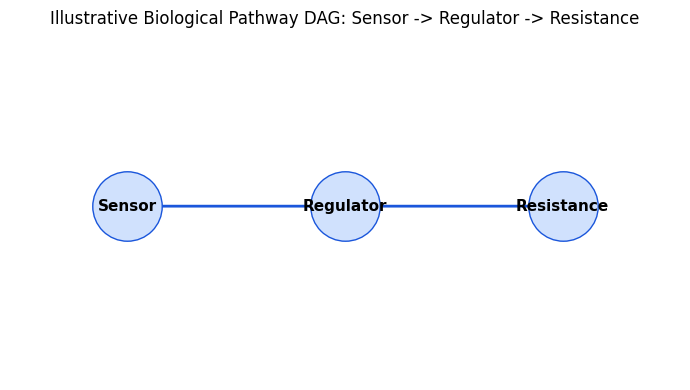

In [7]:
# Section 7: Causal Reasoning & Interventional Distributions
# Illustrative 3-node causal motif with synthetic CPDs demonstrating Pearl do-calculus.
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

bn = DiscreteBayesianNetwork([('Sensor', 'Regulator'), ('Regulator', 'Resistance')])

cpd_sensor = TabularCPD(variable='Sensor', variable_card=2, values=[[0.70], [0.30]])
cpd_regulator = TabularCPD(
    variable='Regulator', variable_card=2,
    values=[[0.85, 0.20],
            [0.15, 0.80]],
    evidence=['Sensor'], evidence_card=[2]
)
cpd_resistance = TabularCPD(
    variable='Resistance', variable_card=2,
    values=[[0.80, 0.15],
            [0.20, 0.85]],
    evidence=['Regulator'], evidence_card=[2]
)

bn.add_cpds(cpd_sensor, cpd_regulator, cpd_resistance)
assert bn.check_model()

infer = VariableElimination(bn)
p_res_base = float(infer.query(['Resistance']).values[1])
p_res_obs = float(infer.query(['Resistance'], evidence={'Sensor': 1}).values[1])

bn_do = bn.copy()
bn_do.remove_edges_from([('Sensor', 'Regulator')])
cpd_reg_do = TabularCPD(variable='Regulator', variable_card=2, values=[[0.0], [1.0]])
bn_do.add_cpds(cpd_sensor, cpd_reg_do, cpd_resistance)
p_res_do = float(VariableElimination(bn_do).query(['Resistance']).values[1])

df_do_calculus = pd.DataFrame([
    {'Query (Illustrative Synthetic CPDs)': 'Baseline Marginal P(Resistance = 1)', 'Probability': round(p_res_base, 4), 'Delta vs Baseline': 0.0},
    {'Query (Illustrative Synthetic CPDs)': 'Observational P(Resistance = 1 | Sensor = 1)', 'Probability': round(p_res_obs, 4), 'Delta vs Baseline': round(p_res_obs - p_res_base, 4)},
    {'Query (Illustrative Synthetic CPDs)': 'Interventional P(Resistance = 1 | do(Regulator = 1))', 'Probability': round(p_res_do, 4), 'Delta vs Baseline': round(p_res_do - p_res_base, 4)},
])
display(df_do_calculus)

fig, ax = plt.subplots(figsize=(7, 4))
pos = {'Sensor': (0, 0.5), 'Regulator': (1, 0.5), 'Resistance': (2, 0.5)}
nx.draw_networkx_nodes(bn, pos, node_size=2500, node_color='#D0E1FD', edgecolors='#1A56DB', ax=ax)
nx.draw_networkx_labels(bn, pos, font_size=11, font_weight='bold', ax=ax)
nx.draw_networkx_edges(bn, pos, arrowstyle='->', arrowsize=25, edge_color='#1A56DB', width=2, ax=ax)
ax.set_title('Illustrative Biological Pathway DAG: Sensor -> Regulator -> Resistance', fontsize=12)
ax.margins(0.2)
plt.axis('off')
plt.tight_layout()
bn_fig_path = REPORTS_DIR / 'dl_biocause_bayesian_dag_motif.png'
plt.savefig(bn_fig_path, dpi=300)
plt.show()


In [8]:
# Section 8: Export Master Deliverables
master_benchmark_path = REPORTS_DIR / 'dl_final_benchmark_summary.csv'
df_benchmark.to_csv(master_benchmark_path, index=False)

master_ablation_path = REPORTS_DIR / 'dl_ablation_summary.csv'
df_ablations.to_csv(master_ablation_path, index=False)

df_bench_read = pd.read_csv(master_benchmark_path)
df_abl_read = pd.read_csv(master_ablation_path)

assert not df_bench_read.empty and len(df_bench_read) == len(df_benchmark), 'Benchmark read-back mismatch'
assert not df_abl_read.empty and len(df_abl_read) == len(df_ablations), 'Ablation read-back mismatch'
assert (REPORTS_DIR / 'dl_biocause_pr_roc_curves.png').exists(), 'Missing PR/ROC figure'
assert (REPORTS_DIR / 'dl_biocause_bayesian_dag_motif.png').exists(), 'Missing Bayesian DAG figure'


## 5. Expected Outputs & Evaluation Criteria

- `reports/dl_final_benchmark_summary.csv`: Master comparison table.
- `reports/dl_ablation_summary.csv`: Systematic ablation results table.
- High-resolution visual figures: Comparative PR curves, ROC curves, and illustrative Bayesian DAG motif.
- **Evaluation Criteria**: Rigorous empirical validation comparing Phase 1 AML baselines, Phase 2 DL models, and hybrid fusion across candidate extraction and graph synthesis.
